# Hodgkin-Huxley Neuron Simulator
### Notebook 02 — Parameter Sweep & f-I Curve

In notebook 01 we implemented the model and observed that firing behaviour
changes with injected current. Here we formalise that observation.

We will:
1. Run the simulation across a range of I_ext values
2. Measure the firing rate at each value
3. Plot the f-I curve (firing frequency vs injected current)
4. Identify the bifurcation point — the threshold where silence becomes firing


## Setup

We import the same libraries as notebook 01, plus we redefine the model here
so this notebook runs independently without needing to import from notebook 01.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# --- Rate functions ---
def alpha_m(V): return 0.1 * (25 - V) / (np.exp((25 - V) / 10) - 1)
def beta_m(V):  return 4.0 * np.exp(-V / 18)
def alpha_h(V): return 0.07 * np.exp(-V / 20)
def beta_h(V):  return 1.0 / (np.exp((30 - V) / 10) + 1)
def alpha_n(V): return 0.01 * (10 - V) / (np.exp((10 - V) / 10) - 1)
def beta_n(V):  return 0.125 * np.exp(-V / 80)

# --- Parameters ---
C_m=1.0; g_Na=120.0; g_K=36.0; g_L=0.3
E_Na=115.0; E_K=-12.0; E_L=10.6

# --- Model ---
def hodgkin_huxley(t, state, I_ext):
    V, m, h, n = state
    I_Na = g_Na * m**3 * h * (V - E_Na)
    I_K  = g_K  * n**4      * (V - E_K)
    I_L  = g_L              * (V - E_L)
    dV = (I_ext - I_Na - I_K - I_L) / C_m
    dm = alpha_m(V)*(1-m) - beta_m(V)*m
    dh = alpha_h(V)*(1-h) - beta_h(V)*h
    dn = alpha_n(V)*(1-n) - beta_n(V)*n
    return [dV, dm, dh, dn]

# --- Initial conditions ---
V0 = 0.0
m0 = alpha_m(V0)/(alpha_m(V0)+beta_m(V0))
h0 = alpha_h(V0)/(alpha_h(V0)+beta_h(V0))
n0 = alpha_n(V0)/(alpha_n(V0)+beta_n(V0))
initial_state = [V0, m0, h0, n0]

print("model ready")

model ready


## Spike detection

To measure firing rate we need to detect spikes automatically.
A spike is defined as the voltage crossing a threshold of 50 mV upward.
We count how many times this happens and divide by the simulation duration.

In [3]:
def count_spikes(V_trace, threshold=50.0):
    """Count upward threshold crossings in a voltage trace."""
    crossings = 0
    for i in range(1, len(V_trace)):
        if V_trace[i-1] < threshold and V_trace[i] >= threshold:
            crossings += 1
    return crossings

def simulate(I_ext, t_end=200):
    """Run simulation and return voltage trace."""
    t_eval = np.linspace(0, t_end, t_end * 100)
    sol = solve_ivp(
        hodgkin_huxley,
        [0, t_end],
        initial_state,
        t_eval=t_eval,
        args=(I_ext,),
        method='RK45',
        max_step=0.05
    )
    return sol.t, sol.y[0]

## The sweep

We run the simulation for each value of I_ext from 0 to 50 µA/cm²
in steps of 0.5. For each run we measure the firing rate in Hz.
This takes about 30–60 seconds to complete.

In [4]:
I_values = np.arange(0, 50.5, 0.5)
firing_rates = []

for I in I_values:
    t, V = simulate(I, t_end=200)
    n_spikes = count_spikes(V)
    rate_hz = (n_spikes / 200) * 1000  # convert from per ms to Hz
    firing_rates.append(rate_hz)
    print(f"I = {I:.1f} → {rate_hz:.1f} Hz")

firing_rates = np.array(firing_rates)
print("\ndone.")

I = 0.0 → 0.0 Hz
I = 0.5 → 0.0 Hz
I = 1.0 → 0.0 Hz
I = 1.5 → 0.0 Hz
I = 2.0 → 0.0 Hz
I = 2.5 → 5.0 Hz
I = 3.0 → 5.0 Hz
I = 3.5 → 5.0 Hz
I = 4.0 → 5.0 Hz
I = 4.5 → 5.0 Hz
I = 5.0 → 5.0 Hz
I = 5.5 → 5.0 Hz
I = 6.0 → 10.0 Hz
I = 6.5 → 55.0 Hz
I = 7.0 → 60.0 Hz
I = 7.5 → 60.0 Hz
I = 8.0 → 65.0 Hz
I = 8.5 → 65.0 Hz
I = 9.0 → 65.0 Hz
I = 9.5 → 70.0 Hz
I = 10.0 → 70.0 Hz
I = 10.5 → 70.0 Hz
I = 11.0 → 70.0 Hz
I = 11.5 → 75.0 Hz
I = 12.0 → 75.0 Hz
I = 12.5 → 75.0 Hz
I = 13.0 → 75.0 Hz
I = 13.5 → 80.0 Hz
I = 14.0 → 80.0 Hz
I = 14.5 → 80.0 Hz
I = 15.0 → 80.0 Hz
I = 15.5 → 80.0 Hz
I = 16.0 → 80.0 Hz
I = 16.5 → 85.0 Hz
I = 17.0 → 85.0 Hz
I = 17.5 → 85.0 Hz
I = 18.0 → 85.0 Hz
I = 18.5 → 85.0 Hz
I = 19.0 → 85.0 Hz
I = 19.5 → 90.0 Hz
I = 20.0 → 90.0 Hz
I = 20.5 → 90.0 Hz
I = 21.0 → 90.0 Hz
I = 21.5 → 90.0 Hz
I = 22.0 → 90.0 Hz
I = 22.5 → 90.0 Hz
I = 23.0 → 90.0 Hz
I = 23.5 → 95.0 Hz
I = 24.0 → 95.0 Hz
I = 24.5 → 95.0 Hz
I = 25.0 → 95.0 Hz
I = 25.5 → 95.0 Hz
I = 26.0 → 95.0 Hz
I = 26.5 → 95.0 Hz
I = 27

## f-I curve and bifurcation point

The plot below shows firing frequency as a function of injected current.
The point where the curve lifts off zero is the bifurcation point —
the critical current at which the neuron transitions from silence to rhythmic firing.

Bifurcation point: I = 2.5 µA/cm²


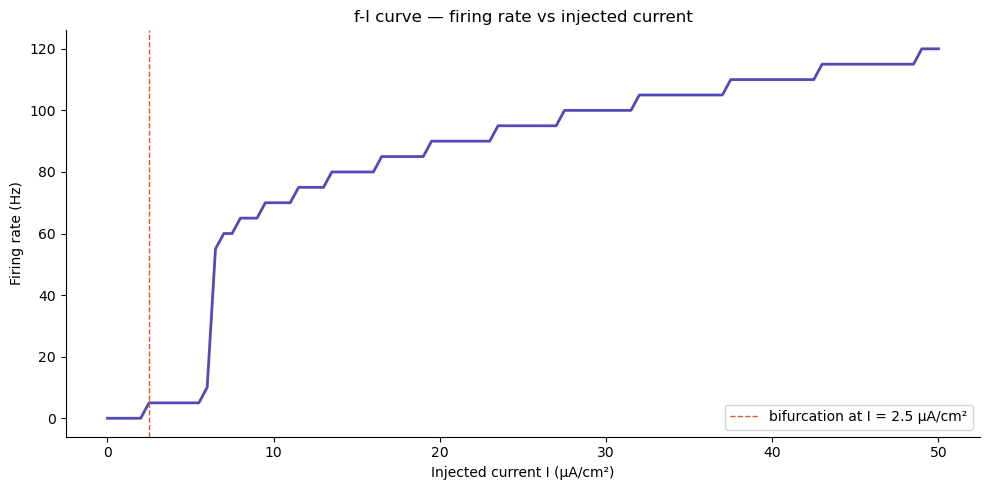

In [5]:
# find bifurcation point — first I where firing rate > 0
bifurcation_idx = np.where(firing_rates > 0)[0]
if len(bifurcation_idx) > 0:
    I_bifurcation = I_values[bifurcation_idx[0]]
    print(f"Bifurcation point: I = {I_bifurcation} µA/cm²")

fig, ax = plt.subplots()
ax.plot(I_values, firing_rates, color='#534AB7', linewidth=2)
ax.axvline(I_bifurcation, color='#D85A30', linewidth=1,
           linestyle='--', label=f'bifurcation at I = {I_bifurcation} µA/cm²')
ax.set_xlabel('Injected current I (µA/cm²)')
ax.set_ylabel('Firing rate (Hz)')
ax.set_title('f-I curve — firing rate vs injected current')
ax.legend()
plt.tight_layout()
plt.savefig('../figures/fi_curve.png', dpi=150)
plt.show()